# Hospital patient data visualization

This notebook explores the cleaned patient records with a small set of charts chosen to answer practical questions about service volume, disease mix, patient experience, and operational measures. It reads `clean_patients_cleaned.csv` and does not change the source file.

The dataset contains 40,596 records from June 2026. OPD and IPD use different time fields: OPD waiting time is zero for IPD records, and room-allocation time is zero for OPD records. For that reason, service-specific time analyses below use only the relevant service. These are descriptive views of recorded data, not causal or clinical conclusions.


## 1. Load the cleaned data

In [ ]:
from pathlib import Path
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

DATA_FILE = Path.cwd() / "clean_patients_cleaned.csv"
df = pd.read_csv(DATA_FILE, parse_dates=["admission_date", "discharge_date"])

sns.set_theme(style="whitegrid", palette="deep")
print(f"{len(df):,} records | {df['admission_date'].min():%d %b %Y} to {df['admission_date'].max():%d %b %Y}")
df.head()


## 2. Matplotlib charts

### Line chart: daily admissions

Counts each record by admission day. This shows short-term volume changes across the month; it does not predict future demand.

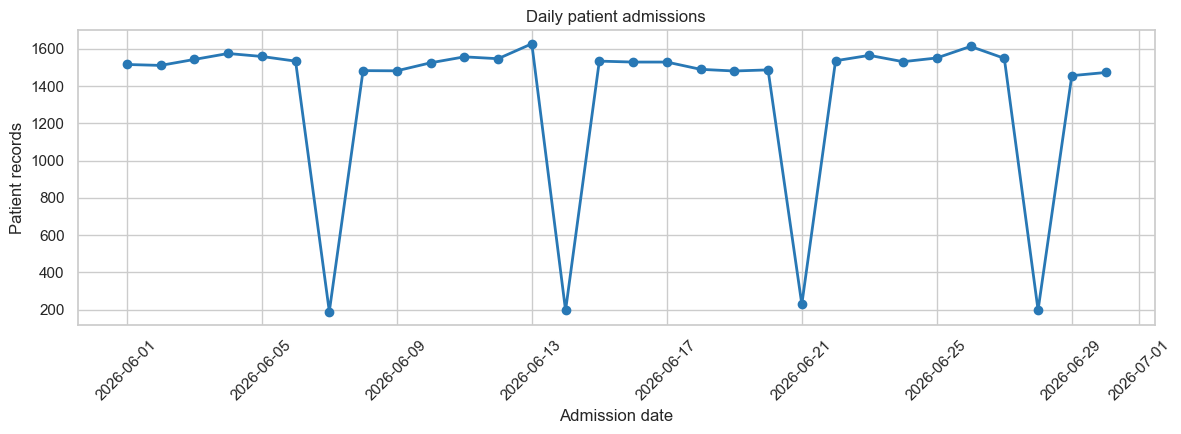

In [2]:
daily_admissions = df.groupby(df["admission_date"].dt.date).size()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily_admissions.index, daily_admissions.values, marker="o", linewidth=2, color="#2878B5")
ax.set(title="Daily patient admissions", xlabel="Admission date", ylabel="Patient records")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()


Box plot: Patient ratings by serivce





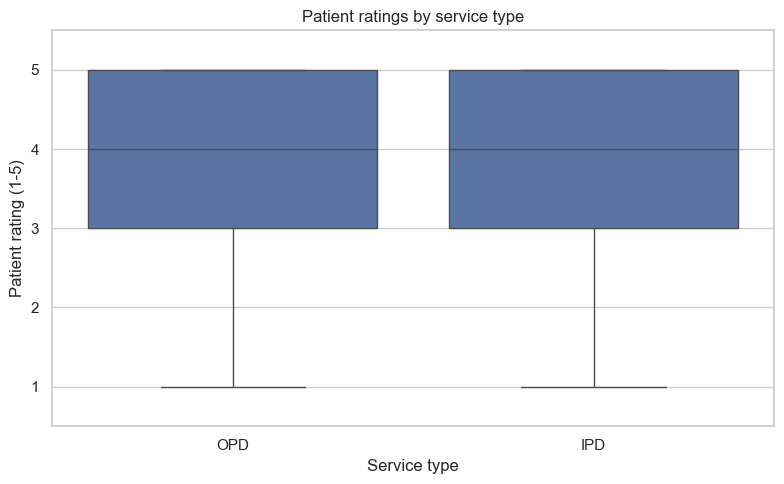

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="patient_type", y="patient_rating", order=["OPD", "IPD"],
            showfliers=False, ax=ax)
ax.set(ylim=(0.5, 5.5), yticks=[1, 2, 3, 4, 5],
       title="Patient ratings by service type", xlabel="Service type",
       ylabel="Patient rating (1-5)")
fig.tight_layout()
plt.show()

### Bar chart: most frequent diseases

Shows the ten disease labels with the most records. A horizontal bar chart keeps the labels readable; the remaining diseases are intentionally omitted from this focused view.

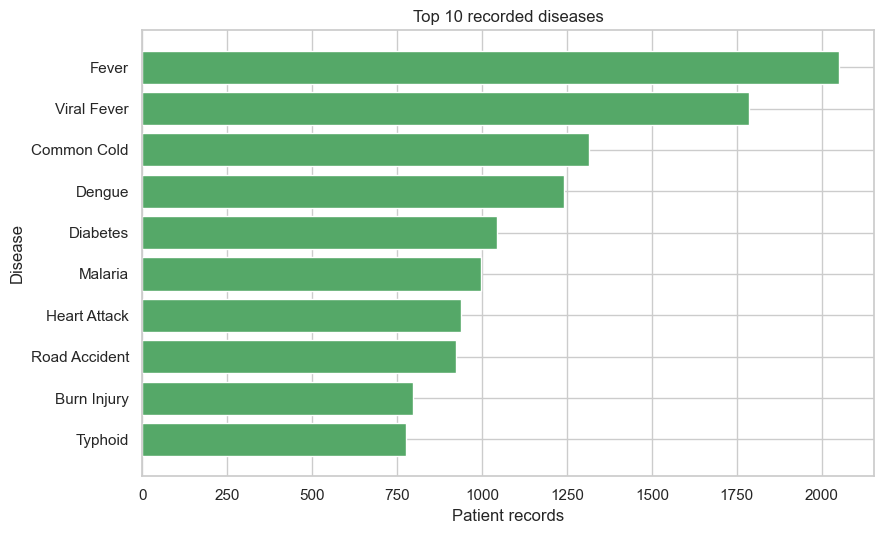

In [4]:
top_diseases = df["disease"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_diseases.index, top_diseases.values, color="#55A868")
ax.set(title="Top 10 recorded diseases", xlabel="Patient records", ylabel="Disease")
fig.tight_layout()
plt.show()


### Pie chart: OPD/IPD service mix

Shows each service type's share of all records. The two categories make this chart readable; counts are printed with the percentages so the denominator is clear.

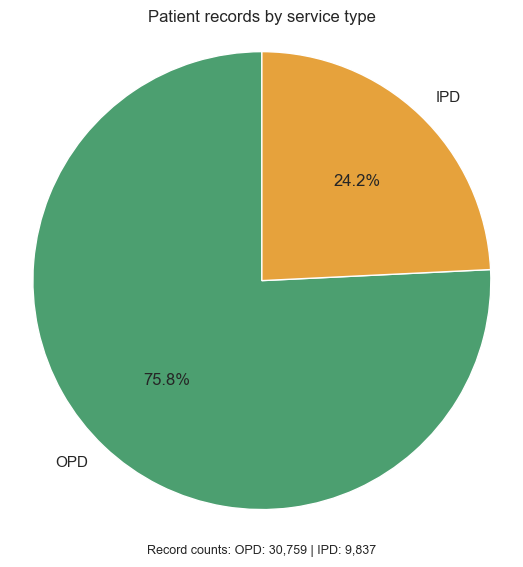

In [5]:
service_counts = df["patient_type"].value_counts().reindex(["OPD", "IPD"])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(service_counts.values, labels=service_counts.index, autopct="%1.1f%%", startangle=90,
       colors=["#4C9F70", "#E6A23C"], wedgeprops={"edgecolor": "white", "linewidth": 1})
ax.set_title("Patient records by service type")
ax.text(0, -1.18, "Record counts: " + " | ".join(f"{k}: {v:,}" for k, v in service_counts.items()),
        ha="center", va="center", fontsize=9)
ax.axis("equal")
plt.show()


## 3. Seaborn statistical visualizations

### Box plot: treatment cost by service type

Compares the median and spread of treatment costs for OPD and IPD. Costs are highly right-skewed, so the vertical axis uses a logarithmic scale; the box summarizes the middle half of observations and points beyond the whiskers represent high or low values.

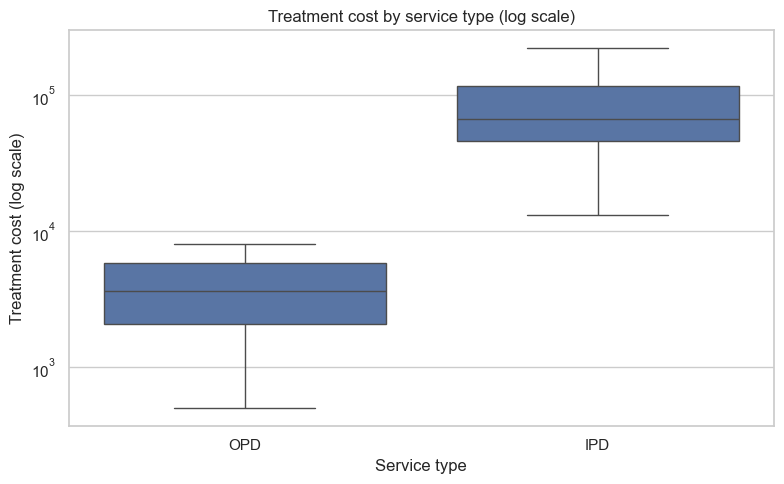

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="patient_type", y="treatment_cost", order=["OPD", "IPD"], showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set(title="Treatment cost by service type (log scale)", xlabel="Service type", ylabel="Treatment cost (log scale)")
fig.tight_layout()
plt.show()


### Violin plot: patient ratings by service type

Compares rating distributions across OPD and IPD. The violin width indicates where ratings are concentrated; the inner box marks the median and quartiles. Ratings are discrete from 1 to 5, so the distribution is best read as concentrations at those values.

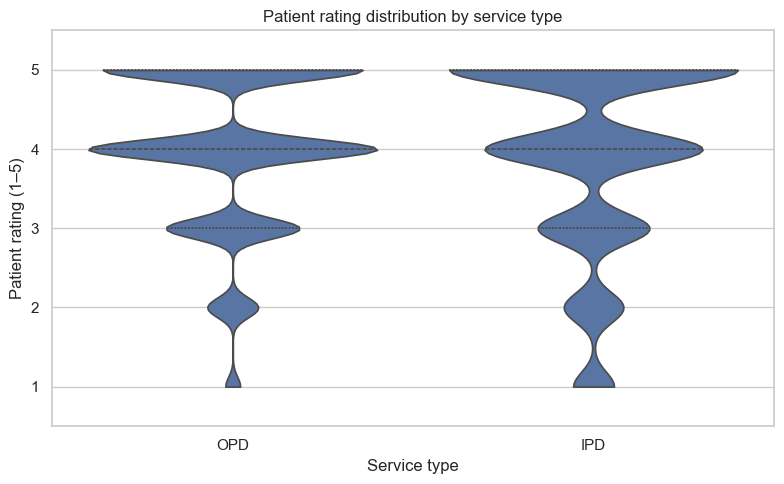

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="patient_type", y="patient_rating", order=["OPD", "IPD"],
               inner="quart", cut=0, density_norm="width", ax=ax)
ax.set(ylim=(0.5, 5.5), yticks=[1, 2, 3, 4, 5], title="Patient rating distribution by service type",
       xlabel="Service type", ylabel="Patient rating (1–5)")
fig.tight_layout()
plt.show()


### Histogram with KDE: age distribution

Shows how patient ages are distributed. The histogram gives record counts by age range, while the KDE curve is a smoothed estimate of the distribution's shape. The curve is a guide, especially because age is recorded in whole years.

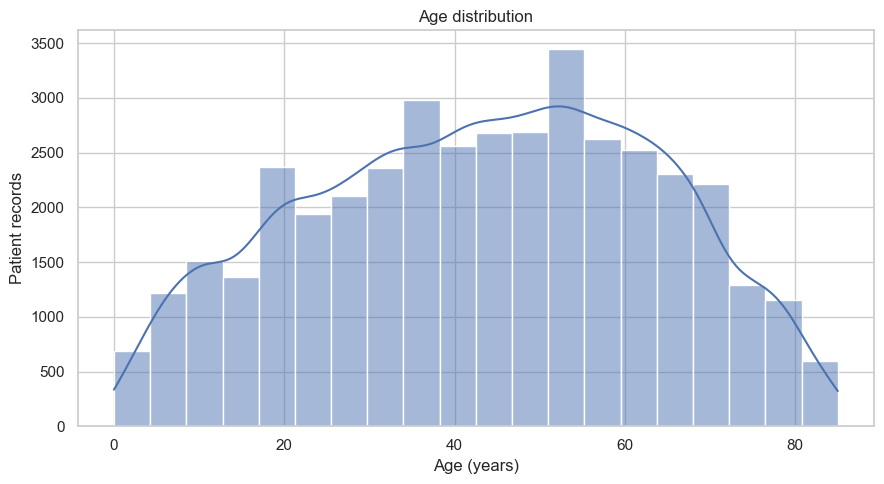

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="age", bins=20, kde=True, color="#4C72B0", ax=ax)
ax.set(title="Age distribution", xlabel="Age (years)", ylabel="Patient records")
fig.tight_layout()
plt.show()


### Correlation heatmap: IPD operational measures

Displays pairwise Pearson correlations among IPD age, treatment cost, room-allocation time, and patient rating. Filtering to IPD avoids mixing real room-allocation measurements with OPD's structural zeroes. Correlation describes linear association, does not imply cause, and can be affected by other patient and treatment factors.

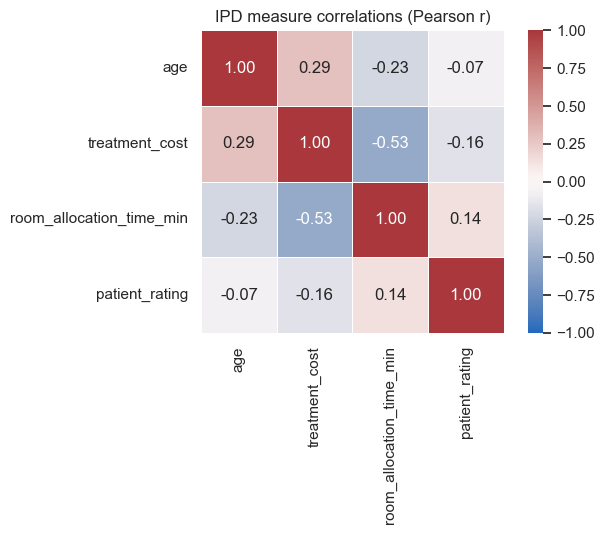

In [9]:
ipd = df.loc[df["patient_type"].eq("IPD"),
             ["age", "treatment_cost", "room_allocation_time_min", "patient_rating"]]
correlations = ipd.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("IPD measure correlations (Pearson r)")
fig.tight_layout()
plt.show()


### Pair plot: relationships within OPD records

Shows pairwise scatterplots and one-variable distributions for age, log-transformed treatment cost, OPD waiting time, and patient rating. A random sample keeps the figure readable and responsive. Each row remains one record; repeated patient IDs may occur, and the plots do not adjust for those repeated observations.

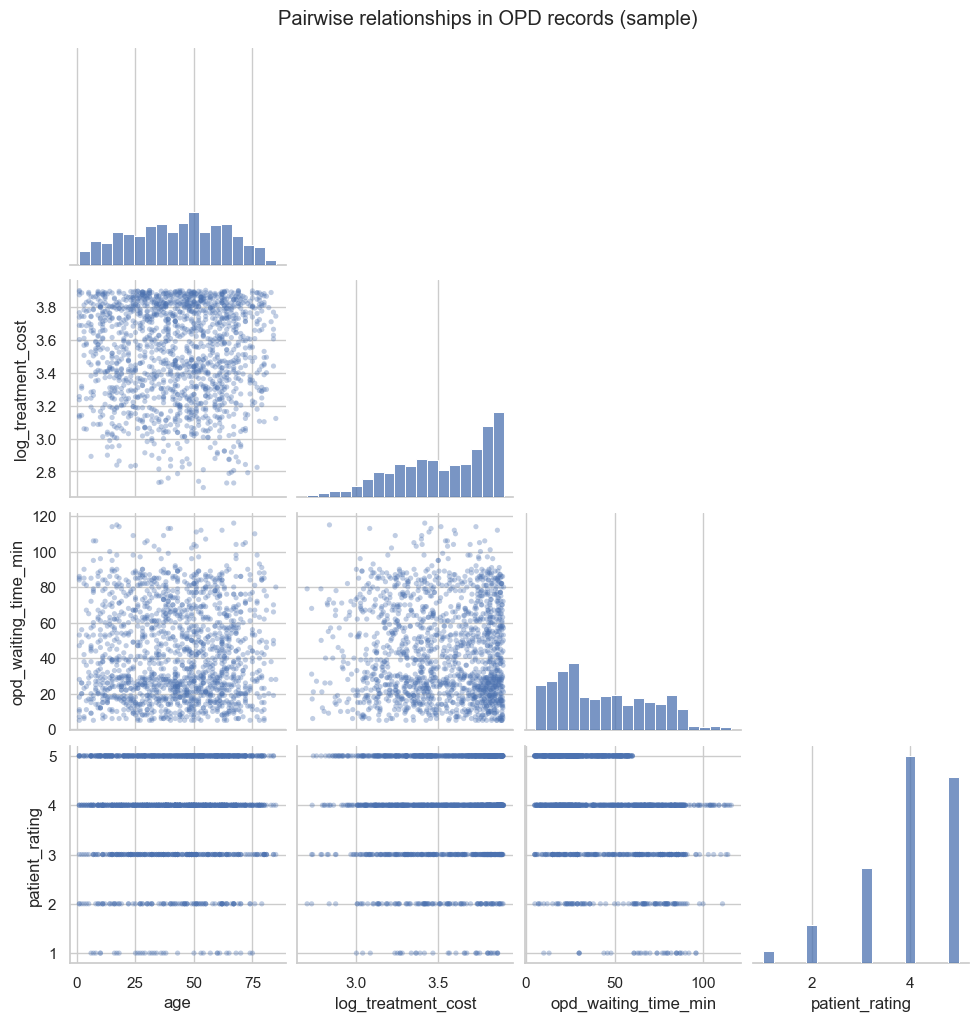

In [10]:
opd_pair = df.loc[df["patient_type"].eq("OPD"),
                  ["age", "treatment_cost", "opd_waiting_time_min", "patient_rating"]].copy()
opd_pair["log_treatment_cost"] = __import__("numpy").log10(opd_pair.pop("treatment_cost"))
pair_sample = opd_pair.sample(n=min(1500, len(opd_pair)), random_state=42)
g = sns.pairplot(pair_sample, vars=["age", "log_treatment_cost", "opd_waiting_time_min", "patient_rating"],
                 corner=True, plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"},
                 diag_kind="hist", diag_kws={"bins": 18})
g.fig.suptitle("Pairwise relationships in OPD records (sample)", y=1.02)
plt.show()


### Scatter plot: OPD waiting time and rating

Plots OPD waiting time against patient rating to inspect whether these measures tend to move together. The points are semi-transparent to make dense regions visible. Any apparent pattern is an association in these records, not evidence that waiting time caused a rating.

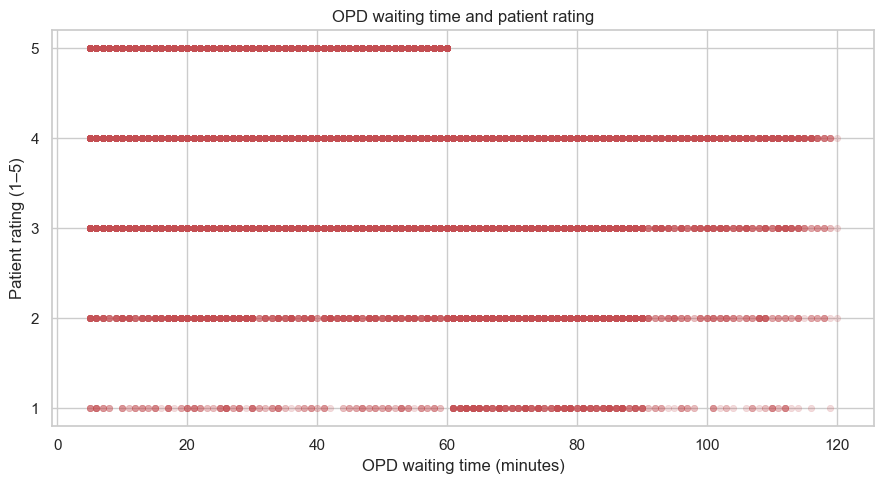

In [11]:
opd_scatter = df.loc[df["patient_type"].eq("OPD"), ["opd_waiting_time_min", "patient_rating"]]
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=opd_scatter, x="opd_waiting_time_min", y="patient_rating",
                alpha=0.2, s=22, color="#C44E52", edgecolor=None, ax=ax)
ax.set(title="OPD waiting time and patient rating", xlabel="OPD waiting time (minutes)",
       ylabel="Patient rating (1–5)", yticks=[1, 2, 3, 4, 5])
fig.tight_layout()
plt.show()


## Reading these charts

These plots summarize the records in this cleaned file. They do not establish causes, forecast later months, or validate clinical outcomes. The June-only date range limits the line chart to within-month patterns, and the disease chart reports recorded labels rather than verified diagnoses. Repeated patient IDs may represent multiple records, so counts here are record counts rather than confirmed unique-patient counts.